# A/B Test Project: Digital Wallet Checkout

> **Simulated data.** This is a personal portfolio project. The data is generated by code in this notebook; it is not from a real company or product.

**Scenario.** An e-commerce checkout currently makes buyers type in card details (control). The treatment adds a one-tap digital wallet button. Should we ship it?

**What this notebook covers**

1. Experiment design: hypothesis, metrics, power analysis, test duration
2. Simulating reproducible data
3. Validity checks (sample ratio mismatch, covariate balance)
4. Primary metric analysis: two-proportion z-test, lift, 95% confidence interval
5. Secondary and guardrail metrics
6. Exploratory segment analysis with a multiple-comparison correction
7. Chart and recommendation

Run the cells top to bottom. Change the settings in the config cell to explore other scenarios.

## 0. Setup and configuration

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from scipy import stats
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize, proportions_ztest

# ---- Experiment design assumptions ----
SEED = 42
ALPHA = 0.05                    # significance level
POWER = 0.80                    # probability of detecting the MDE if it is real
BASELINE_CONVERSION = 0.60      # assumed control conversion (completed orders / checkout starts)
MDE = 0.02                      # minimum detectable effect, absolute (+2 percentage points)
DAILY_CHECKOUT_STARTS = 5_000   # assumed daily traffic entering the experiment

# ---- "Ground truth" used ONLY to generate the data ----
# In a real experiment you never know these. Try TRUE_LIFT = 0 to see an inconclusive test.
TRUE_LIFT = 0.025               # average absolute lift from the wallet button
SHARE_MOBILE = 0.65
SHARE_NEW_BUYERS = 0.40
TREATMENT_FAIL_RATE = 0.030     # payment failure rate in treatment (control is 0.030). Try 0.045.
CONTROL_FAIL_RATE = 0.030

## 1. Experiment design

**Hypothesis.** Adding a one-tap wallet button increases checkout conversion.

| Type | Metric |
|---|---|
| Primary | Checkout conversion rate (completed orders / checkout starts) |
| Secondary | Time to complete checkout, average order value |
| Guardrail | Payment failure rate (we must not win on conversion while hurting reliability) |

**Power analysis.** How many users per group do we need to detect a +2 percentage point lift on a 60% baseline, with 80% power at a 5% significance level?

In [2]:
def design_experiment():
    effect_size = proportion_effectsize(BASELINE_CONVERSION + MDE, BASELINE_CONVERSION)
    n_per_group = NormalIndPower().solve_power(
        effect_size=effect_size, alpha=ALPHA, power=POWER, ratio=1.0, alternative="two-sided"
    )
    n_per_group = math.ceil(n_per_group)
    days_needed = math.ceil(2 * n_per_group / DAILY_CHECKOUT_STARTS)
    # Run at least 2 full weeks so every weekday appears twice
    test_days = max(days_needed, 14)
    return n_per_group, days_needed, test_days


n_per_group, days_needed, test_days = design_experiment()
print(f"Required sample: {n_per_group:,} users per group (alpha={ALPHA}, power={POWER:.0%})")
print(f"At {DAILY_CHECKOUT_STARTS:,} checkout starts/day: {days_needed} days of traffic needed")
print(f"Planned duration: {test_days} days, to cover full weekly cycles")

Required sample: 9,335 users per group (alpha=0.05, power=80%)
At 5,000 checkout starts/day: 4 days of traffic needed
Planned duration: 14 days, to cover full weekly cycles


## 2. Simulate the data

Users are randomly assigned to control or treatment. Conversion depends on device, buyer type, and weekends, and the wallet button helps mobile users more than desktop users. The random generator is created inside the function from `SEED`, so re-running this cell always gives the same data.

In [3]:
def simulate(n_users: int, test_days: int, seed: int = SEED) -> pd.DataFrame:
    rng = np.random.default_rng(seed)

    df = pd.DataFrame({
        "user_id": np.arange(n_users),
        # Random 50/50 assignment (counts differ slightly, as in real life)
        "group": rng.choice(["control", "treatment"], size=n_users),
        "device": rng.choice(["mobile", "desktop"], size=n_users,
                             p=[SHARE_MOBILE, 1 - SHARE_MOBILE]),
        "buyer_type": rng.choice(["new", "returning"], size=n_users,
                                 p=[SHARE_NEW_BUYERS, 1 - SHARE_NEW_BUYERS]),
        "day": rng.integers(0, test_days, size=n_users),
    })
    df["is_weekend"] = (df["day"] % 7).isin([5, 6])

    # Baseline conversion probability with realistic covariate effects
    p = np.full(n_users, BASELINE_CONVERSION)
    p += np.where(df["device"] == "mobile", -0.04, 0.0675)   # mobile converts worse than desktop
    p += np.where(df["buyer_type"] == "new", -0.06, 0.04)    # new buyers convert worse
    p += np.where(df["is_weekend"], 0.01, 0.0)

    # Heterogeneous treatment effect: the wallet helps mobile more than desktop
    lift = np.where(df["device"] == "mobile", TRUE_LIFT * 1.3, TRUE_LIFT * 0.5)
    p = p + np.where(df["group"] == "treatment", lift, 0.0)
    p = np.clip(p, 0.01, 0.99)

    df["converted"] = (rng.random(n_users) < p).astype(int)

    # Secondary: seconds to complete checkout (converted users only); the wallet is faster
    base_sec = np.where(df["group"] == "treatment", 38, 55)
    secs = rng.lognormal(mean=np.log(base_sec), sigma=0.35)
    df["checkout_seconds"] = np.where(df["converted"] == 1, secs, np.nan)

    # Secondary: order value (converted users only); no true effect
    order_value = rng.lognormal(mean=np.log(35), sigma=0.5, size=n_users)
    df["order_value"] = np.where(df["converted"] == 1, order_value, np.nan)

    # Guardrail: payment failure
    fail_rate = np.where(df["group"] == "treatment", TREATMENT_FAIL_RATE, CONTROL_FAIL_RATE)
    df["payment_failed"] = (rng.random(n_users) < fail_rate).astype(int)

    return df


df = simulate(n_users=2 * n_per_group, test_days=test_days)
df.head()

,user_id,group,device,buyer_type,day,is_weekend,converted,checkout_seconds,order_value,payment_failed
0,0,control,desktop,returning,7,False,1,31.948578,20.853953,0
1,1,treatment,mobile,returning,6,True,1,31.259777,62.756576,0
2,2,treatment,mobile,new,7,False,1,47.217064,36.650547,0
3,3,control,mobile,returning,10,False,0,NaN,NaN,0
4,4,control,mobile,returning,12,True,1,69.231868,28.557212,0


## 3. Validity checks (before looking at results)

- **Sample ratio mismatch (SRM).** With a 50/50 split, the group sizes should be close to equal. A very small p-value means assignment or logging is broken and the results can't be trusted.
- **Covariate balance.** Device and buyer-type mix should be similar across groups.

In [4]:
def check_validity(df: pd.DataFrame):
    counts = df["group"].value_counts().reindex(["control", "treatment"])
    chi2, p_srm = stats.chisquare(counts.values, f_exp=[counts.sum() / 2] * 2)
    print(f"Group sizes: control={counts['control']:,}  treatment={counts['treatment']:,}")
    print(f"Sample ratio mismatch: chi2={chi2:.3f}, p={p_srm:.3f} -> "
          f"{'PASS' if p_srm > 0.001 else 'FAIL: investigate assignment before analyzing'}")

    for col in ["device", "buyer_type"]:
        table = pd.crosstab(df[col], df["group"])
        chi2, p, _, _ = stats.chi2_contingency(table)
        print(f"Balance on {col}: p={p:.3f} -> {'PASS' if p > 0.01 else 'CHECK'}")


check_validity(df)

Group sizes: control=9,405  treatment=9,265
Sample ratio mismatch: chi2=1.050, p=0.306 -> PASS
Balance on device: p=0.491 -> PASS
Balance on buyer_type: p=0.439 -> PASS


## 4. Primary metric: checkout conversion

A two-proportion z-test, reported with the absolute lift, relative lift, and a 95% confidence interval. The confidence interval matters as much as the p-value because it shows the range of effect sizes consistent with the data.

In [5]:
def conversion_test(sub: pd.DataFrame, col: str = "converted") -> dict:
    t = sub[sub["group"] == "treatment"][col]
    c = sub[sub["group"] == "control"][col]
    x = np.array([t.sum(), c.sum()])
    n = np.array([len(t), len(c)])
    p_t, p_c = x / n
    z, p_val = proportions_ztest(x, n, alternative="two-sided")
    diff = p_t - p_c
    se = math.sqrt(p_t * (1 - p_t) / n[0] + p_c * (1 - p_c) / n[1])
    zcrit = stats.norm.ppf(1 - ALPHA / 2)
    return {
        "n_treatment": int(n[0]), "n_control": int(n[1]),
        "rate_treatment": p_t, "rate_control": p_c,
        "abs_lift": diff, "rel_lift": diff / p_c,
        "ci_low": diff - zcrit * se, "ci_high": diff + zcrit * se,
        "z": z, "p_value": p_val,
    }


def print_result(name: str, r: dict):
    print(name)
    print(f"  Control   : {r['rate_control']:.2%} (n={r['n_control']:,})")
    print(f"  Treatment : {r['rate_treatment']:.2%} (n={r['n_treatment']:,})")
    print(f"  Abs lift  : {r['abs_lift']*100:+.2f} pts "
          f"(95% CI {r['ci_low']*100:+.2f} to {r['ci_high']*100:+.2f})")
    print(f"  Rel lift  : {r['rel_lift']:+.1%}")
    print(f"  z={r['z']:.2f}, p={r['p_value']:.4f}")


primary = conversion_test(df)
print_result("Checkout conversion (overall)", primary)

Checkout conversion (overall)
  Control   : 59.73% (n=9,405)
  Treatment : 62.22% (n=9,265)
  Abs lift  : +2.49 pts (95% CI +1.09 to +3.89)
  Rel lift  : +4.2%
  z=3.49, p=0.0005


## 5. Secondary and guardrail metrics

Secondary metrics explain *why* conversion moved. The guardrail checks that we didn't harm something we care about, like payment reliability.

In [6]:
def welch_test(df: pd.DataFrame, col: str, label: str, unit: str = ""):
    t = df[df["group"] == "treatment"][col].dropna()
    c = df[df["group"] == "control"][col].dropna()
    stat, p = stats.ttest_ind(t, c, equal_var=False)
    print(label)
    print(f"  Control mean: {c.mean():.2f}{unit} | Treatment mean: {t.mean():.2f}{unit} | "
          f"diff={t.mean() - c.mean():+.2f}{unit} (Welch t={stat:.2f}, p={p:.4g})")


welch_test(df, "checkout_seconds", "Time to complete checkout (converted users)", " s")
welch_test(df, "order_value", "Average order value (converted users)", " $")
print()
guard = conversion_test(df, col="payment_failed")
print_result("Guardrail: payment failure rate (want no meaningful increase)", guard)

Time to complete checkout (converted users)
  Control mean: 58.02 s | Treatment mean: 40.13 s | diff=-17.89 s (Welch t=-52.38, p=0)
Average order value (converted users)
  Control mean: 39.41 $ | Treatment mean: 39.88 $ | diff=+0.46 $ (Welch t=1.14, p=0.2522)

Guardrail: payment failure rate (want no meaningful increase)
  Control   : 3.10% (n=9,405)
  Treatment : 3.23% (n=9,265)
  Abs lift  : +0.12 pts (95% CI -0.38 to +0.62)
  Rel lift  : +3.9%
  z=0.48, p=0.6327


## 6. Segments (exploratory only)

Slicing the data into segments creates many chances for a false positive, so p-values are adjusted with a Bonferroni correction. The experiment was sized for the overall effect, so segment results are underpowered. Treat them as hypotheses for a follow-up test, not conclusions.

In [7]:
seg_rows = []
for col in ["device", "buyer_type"]:
    for val in df[col].unique():
        res = conversion_test(df[df[col] == val])
        res["segment"] = f"{col}={val}"
        seg_rows.append(res)

seg = pd.DataFrame(seg_rows)
seg["p_bonferroni"] = (seg["p_value"] * len(seg)).clip(upper=1.0)
seg[["segment", "n_treatment", "rate_control", "rate_treatment",
     "abs_lift", "p_value", "p_bonferroni"]].round(4)

,segment,n_treatment,rate_control,rate_treatment,abs_lift,p_value,p_bonferroni
0,device=desktop,3279,0.6667,0.6810,0.0143,0.2125,0.8499
1,device=mobile,5986,0.5585,0.5900,0.0315,0.0005,0.0019
2,buyer_type=returning,5632,0.6347,0.6616,0.0269,0.0028,0.0112
3,buyer_type=new,3633,0.5408,0.5612,0.0205,0.0771,0.3085


## 7. Chart

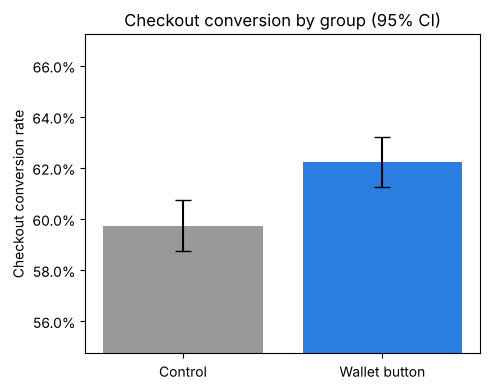

In [8]:
rates, errs = [], []
for g in ["control", "treatment"]:
    s = df[df["group"] == g]["converted"]
    rates.append(s.mean())
    errs.append(1.96 * math.sqrt(s.mean() * (1 - s.mean()) / len(s)))

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(["Control", "Wallet button"], rates, yerr=errs, capsize=6, color=["#999999", "#2a7de1"])
ax.set_ylabel("Checkout conversion rate")
ax.set_title("Checkout conversion by group (95% CI)")
ax.set_ylim(min(rates) - 0.05, max(rates) + 0.05)
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
fig.tight_layout()
fig.savefig("conversion_by_group.png", dpi=150)
plt.show()

## 8. Decision

A simple, transparent rule: ship if the primary metric is significantly positive and no guardrail got significantly worse.

In [9]:
sig = primary["p_value"] < ALPHA
guard_ok = not (guard["p_value"] < ALPHA and guard["abs_lift"] > 0)

if sig and primary["abs_lift"] > 0 and guard_ok:
    print(f"SHIP: conversion up {primary['abs_lift']*100:.2f} pts "
          f"(95% CI {primary['ci_low']*100:.2f} to {primary['ci_high']*100:.2f}); guardrails healthy.")
elif not guard_ok:
    print("DO NOT SHIP: a guardrail metric got worse. Investigate payment failures first.")
else:
    print("INCONCLUSIVE: no significant lift. Run longer or test a bigger change.")

# Practical significance: is even the low end of the interval worth the engineering cost?
print(f"Low end of the CI: {primary['ci_low']*100:+.2f} pts -> decide if that is still worth shipping.")

SHIP: conversion up 2.49 pts (95% CI 1.09 to 3.89); guardrails healthy.
Low end of the CI: +1.09 pts -> decide if that is still worth shipping.


## Recommendation memo (edit after you run your own version)

**Decision:** Ship / Don't ship / Run longer

**Why:** One or two sentences on the primary result, with the lift and confidence interval, and what the guardrails showed.

**Segment notes (exploratory):** Which segments look different, and why you would confirm with a follow-up test before acting.

**Risks:** What could make this result misleading (novelty effect, seasonality, simulated assumptions, and so on).

**Next step:** A proposed follow-up test.

---

## Things to try

- Set `TRUE_LIFT = 0` and re-run: you should get an inconclusive result.
- Set `TREATMENT_FAIL_RATE = 0.045` and re-run: the guardrail should block the launch even though conversion rises.
- Change `MDE` to 0.01 and see how the required sample size changes.
- Peek early: analyze only the first 2,000 users per group and see how noisy the conclusion is. This is why you fix the sample size in advance.